Cell A1: locate inputs

In [1]:
import os, glob, json, itertools
import numpy as np, pandas as pd, matplotlib.pyplot as plt

RES = os.path.dirname(glob.glob("/kaggle/input/**/runs/summary_*.csv", recursive=True)[0])
DS = os.path.dirname(glob.glob("/kaggle/input/**/index_v2.csv", recursive=True)[0])
stats = json.load(open(f"{DS}/norm_stats_v2.json"))
CLASSES = stats["classes"]; NC = len(CLASSES)
print("results:", RES); print("dataset:", DS)

results: /kaggle/input/datasets/rahuldevagiri/lulc-m4-results/runs
dataset: /kaggle/input/datasets/rahuldevagiri/lulc-s1-global-v2


Cell A2: load all runs

In [2]:
runs = sorted(d for d in os.listdir(RES) if os.path.isdir(f"{RES}/{d}"))
S, H, CM, ROWS = [], [], {}, None
for r in runs:
    model, seed = r.rsplit("_s", 1)                     # "deeplabv3p_r34_t3_s42" -> ("deeplabv3p_r34_t3", "42")
    S.append(json.load(open(f"{RES}/{r}/summary.json")))
    H.append(pd.read_csv(f"{RES}/{r}/history.csv"))
    z = np.load(f"{RES}/{r}/val_cms.npz")
    if ROWS is None:
        ROWS = z["rows"]
    assert (z["rows"] == ROWS).all(), f"{r}: different val sample order"
    CM.setdefault(model, []).append(z["cms"].astype(np.int64))
MODELS = list(CM)
summ, hist = pd.DataFrame(S), pd.concat(H, ignore_index=True)
print("models:", {m: len(v) for m, v in CM.items()}, "| val samples:", len(ROWS))

models: {'deeplabv3p_r34': 3, 'deeplabv3p_r34_t3': 3, 'segformer_b2': 3, 'segformer_b2_t3': 3} | val samples: 6895


Cell A3: mean ± SD over seeds

In [3]:
cols = ["val_mIoU", "pixel_acc", "macro_F1"] + [f"IoU_{c}" for c in CLASSES] + \
       ["best_epoch", "train_min", "peak_mem_GB", "params_M"]
agg = summ.groupby("model")[cols].agg(["mean", "std"])
seed_table = pd.DataFrame({c: agg[c]["mean"].round(3).astype(str) + " ± " + agg[c]["std"].round(3).astype(str)
                           for c in cols})
seed_table.T

model,deeplabv3p_r34,deeplabv3p_r34_t3,segformer_b2,segformer_b2_t3
val_mIoU,0.49 ± 0.002,0.523 ± 0.002,0.507 ± 0.001,0.548 ± 0.001
pixel_acc,0.648 ± 0.002,0.683 ± 0.003,0.672 ± 0.0,0.706 ± 0.001
macro_F1,0.644 ± 0.002,0.673 ± 0.002,0.659 ± 0.001,0.696 ± 0.001
IoU_Tree,0.593 ± 0.004,0.627 ± 0.003,0.622 ± 0.0,0.651 ± 0.006
IoU_Shrub/Grass,0.323 ± 0.005,0.375 ± 0.009,0.366 ± 0.002,0.397 ± 0.01
IoU_Cropland,0.509 ± 0.005,0.577 ± 0.004,0.545 ± 0.005,0.611 ± 0.01
IoU_Built-up,0.63 ± 0.003,0.642 ± 0.003,0.645 ± 0.001,0.656 ± 0.002
IoU_Bare,0.364 ± 0.007,0.387 ± 0.007,0.367 ± 0.01,0.421 ± 0.014
IoU_Water,0.708 ± 0.003,0.743 ± 0.006,0.711 ± 0.002,0.763 ± 0.018
IoU_Wetland,0.301 ± 0.016,0.309 ± 0.006,0.289 ± 0.013,0.34 ± 0.014


Cell A4: paired cluster bootstrap over 5° cells

In [4]:
idx = pd.read_csv(f"{DS}/index_v2.csv")
val = idx.loc[ROWS].reset_index(drop=True)
assert (val.split == "val").all()

def miou(cm):
    tp = np.diag(cm); ref, pr = cm.sum(1), cm.sum(0)
    iou = np.where(ref > 0, tp / np.maximum(ref + pr - tp, 1), np.nan)
    return np.nanmean(iou)

pooled = {m: np.sum(CM[m], axis=0) for m in MODELS}               # (samples, 7, 7), seeds added
cells = np.array([f"{int(a // 5)}_{int(b // 5)}" for a, b in zip(val.lat, val.lon)])
uc, inv = np.unique(cells, return_inverse=True)
cellcm = {m: np.zeros((len(uc), NC, NC)) for m in MODELS}
for m in MODELS:
    np.add.at(cellcm[m], inv, pooled[m])
print("independent units (5-degree cells):", len(uc))

B, rng = 2000, np.random.default_rng(0)
boot = {m: np.empty(B) for m in MODELS}
for b in range(B):
    w = np.bincount(rng.integers(0, len(uc), len(uc)), minlength=len(uc))
    for m in MODELS:
        boot[m][b] = miou(np.tensordot(w, cellcm[m], axes=1))

ci = pd.DataFrame([{"model": m, "val_mIoU_pooled": round(miou(cellcm[m].sum(0)), 4),
                    "CI_low": round(np.percentile(boot[m], 2.5), 4),
                    "CI_high": round(np.percentile(boot[m], 97.5), 4)} for m in MODELS])
pairs = pd.DataFrame([{"A": a, "B": b, "mean_diff": round((boot[a] - boot[b]).mean(), 4),
                       "CI_low": round(np.percentile(boot[a] - boot[b], 2.5), 4),
                       "CI_high": round(np.percentile(boot[a] - boot[b], 97.5), 4),
                       "P(A>B)": round((boot[a] > boot[b]).mean(), 3)}
                      for a, b in itertools.permutations(MODELS, 2) if boot[a].mean() >= boot[b].mean()])
print(ci.to_string(index=False)); print(); print(pairs.to_string(index=False))
ci.to_csv("/kaggle/working/M4_bootstrap_ci.csv", index=False)
pairs.to_csv("/kaggle/working/M4_bootstrap_pairs.csv", index=False)

independent units (5-degree cells): 99
            model  val_mIoU_pooled  CI_low  CI_high
   deeplabv3p_r34           0.4896  0.4561   0.5198
deeplabv3p_r34_t3           0.5228  0.4853   0.5590
     segformer_b2           0.5066  0.4726   0.5398
  segformer_b2_t3           0.5483  0.5103   0.5831

                A                 B  mean_diff  CI_low  CI_high  P(A>B)
deeplabv3p_r34_t3    deeplabv3p_r34     0.0337  0.0240   0.0441   1.000
deeplabv3p_r34_t3      segformer_b2     0.0162  0.0059   0.0278   0.999
     segformer_b2    deeplabv3p_r34     0.0175  0.0056   0.0294   0.998
  segformer_b2_t3    deeplabv3p_r34     0.0590  0.0455   0.0734   1.000
  segformer_b2_t3 deeplabv3p_r34_t3     0.0253  0.0165   0.0343   1.000
  segformer_b2_t3      segformer_b2     0.0416  0.0319   0.0526   1.000


Cell A5: learning curves (mean of seeds)

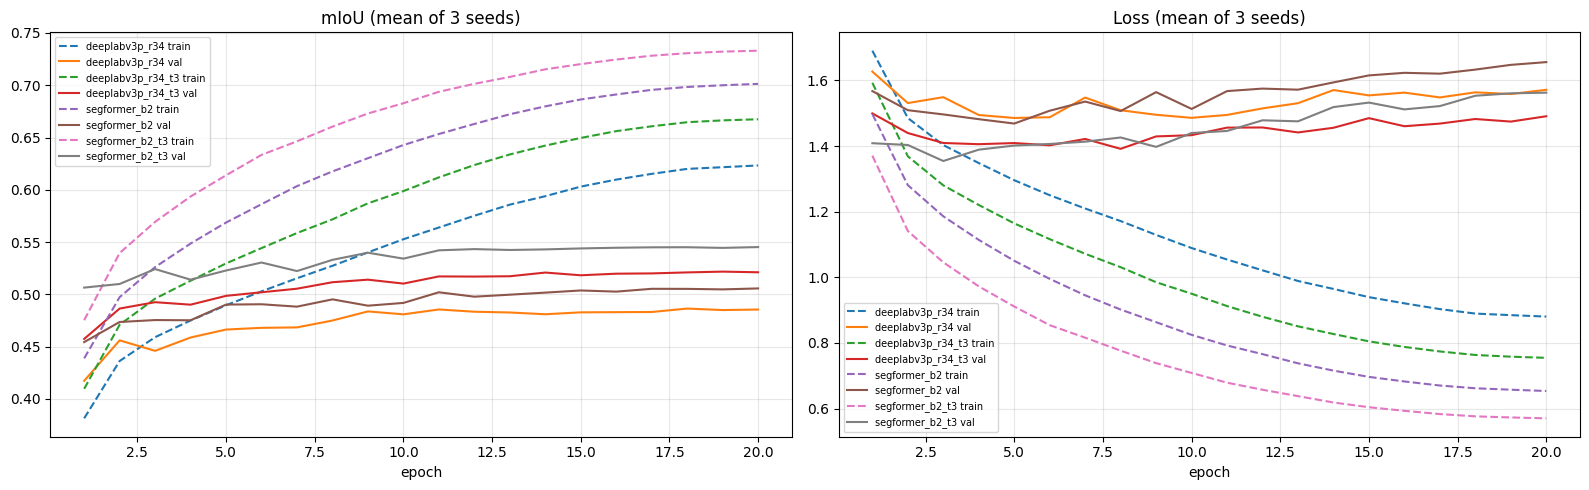

In [5]:
g = hist.groupby(["model", "epoch"])[["train_mIoU", "val_mIoU", "train_loss", "val_loss"]].mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
for m in MODELS:
    d = g[g.model == m]
    ax[0].plot(d.epoch, d.train_mIoU, "--", label=f"{m} train"); ax[0].plot(d.epoch, d.val_mIoU, label=f"{m} val")
    ax[1].plot(d.epoch, d.train_loss, "--", label=f"{m} train"); ax[1].plot(d.epoch, d.val_loss, label=f"{m} val")
ax[0].set_title("mIoU (mean of 3 seeds)"); ax[1].set_title("Loss (mean of 3 seeds)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig("/kaggle/working/M4_curves.png", dpi=120); plt.show()

Cell A6: breakdowns (biome, latitude, terrain, data version)

In [6]:
m1 = pd.read_csv(f"{DS}/points_meta.csv", keep_default_na=False, na_values=[""])[["pid", "biome_name", "slope"]]
m2 = pd.read_json(f"{DS}/points_v2.json")[["pid", "biome_name", "slope"]]
meta = pd.concat([m1, m2]).rename(columns={"pid": "pid_file"})
v = val[["pid_file", "lat", "version"]].merge(meta, on="pid_file", how="left")    # keeps sample order
v["lat_zone"] = pd.cut(v.lat.abs(), [0, 23.5, 35, 55, 90], labels=["tropical", "subtropical", "temperate", "boreal/polar"])
v["terrain"] = pd.cut(v.slope, [-1, 5, 15, 90], labels=["flat <5", "hilly 5-15", "mountain >15"])

def breakdown(col):
    rows = []
    for grp, gi in v.groupby(col, observed=True):
        r = {col: grp, "n_locations": gi.pid_file.nunique(), "n_samples": len(gi)}
        for m in MODELS:
            r[m] = round(miou(pooled[m][gi.index.values].sum(0)), 3)
        rows.append(r)
    return pd.DataFrame(rows)

for col in ["version", "biome_name", "lat_zone", "terrain"]:
    t = breakdown(col); t.to_csv(f"/kaggle/working/M4_by_{col}.csv", index=False)
    print(f"\n=== by {col} ===\n", t.to_string(index=False))


=== by version ===
 version  n_locations  n_samples  deeplabv3p_r34  deeplabv3p_r34_t3  segformer_b2  segformer_b2_t3
     v1          257       3070           0.513              0.540         0.531            0.572
     v2          319       3825           0.463              0.502         0.480            0.523

=== by biome_name ===
                                               biome_name  n_locations  n_samples  deeplabv3p_r34  deeplabv3p_r34_t3  segformer_b2  segformer_b2_t3
                                    Boreal Forests/Taiga           39        466           0.439              0.496         0.475            0.553
                              Deserts & Xeric Shrublands           28        336           0.353              0.362         0.381            0.408
                           Flooded Grasslands & Savannas           46        552           0.378              0.411         0.370            0.415
                                               Mangroves           24    